# Regressão Linear
```
Tema: Impacto da IA e das redes sociais na saúde e no desempenho dos estudantes
```
**Pergunta:** quanto o uso de redes sociais ajuda a explicar a saúde (bem-estar, sono) e o desempenho (frequência, atenção, nota)?

Método: regressão linear (scikit-learn) com separação treino/teste (80/20), métricas R², MAE e RMSE e coeficientes padronizados para comparar o peso de cada variável.

---

In [4]:
import time
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

ARQUIVO = "estudantes.parquet"

inicial = pl.scan_parquet(ARQUIVO)
esquema = inicial.collect_schema()
colunas = esquema.names()
numericas = [c for c, t in esquema.items() if t.is_numeric()]

def candidatas(tokens, entre):
    return [c for c in entre if set(c.split("_")) & tokens]

# Métricas de saúde e desempenho usadas nos resumos
METRICAS = list(dict.fromkeys(
    c for c in ["horas_redes_sociais", "horas_sono", "pontuacao_vicio_digital", "indice_bem_estar",
                "taxa_frequencia_aulas", "capacidade_atencao_minutos", "pontuacao_risco_academico",]
    if c and c in colunas
))

def perfil(lf, grupo):
    """Resumo por grupo: nº de estudantes + média das métricas do tema."""
    return (
        lf.group_by(grupo)
        .agg([pl.len().alias("estudantes")] +
             [pl.col(c).mean().round(2).alias(f"media_{c}") for c in METRICAS])
        .sort(grupo)
    )

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def ajustar(titulo, alvo, feats, graficos=True):
    feats = [f for f in feats if f and f in colunas and f != alvo]
    df = inicial.select(feats + [alvo]).drop_nulls().collect()
    X = df.select(feats).to_numpy()
    y = df[alvo].to_numpy()

    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
    modelo = LinearRegression().fit(Xtr, ytr)
    pred = modelo.predict(Xte)

    r2 = r2_score(yte, pred)
    mae = mean_absolute_error(yte, pred)
    rmse = np.sqrt(mean_squared_error(yte, pred))

    # Coeficientes padronizados (beta): comparáveis entre variáveis
    betas = LinearRegression().fit((X - X.mean(0)) / X.std(0), (y - y.mean()) / y.std()).coef_

    print(f"\n{'=' * 70}\n{titulo}\n{'=' * 70}")
    print(f"n = {df.height:,} | R² (teste) = {r2:.4f} | MAE = {mae:.3f} | RMSE = {rmse:.3f}")
    print(f"Intercepto: {modelo.intercept_:.3f}")
    for f, c, b in zip(feats, modelo.coef_, betas):
        print(f"  {f:35s} coef = {c:+.4f} | beta padronizado = {b:+.4f}")
        print(f"      -> +1 unidade em {f} muda {alvo} em {c:+.3f}, mantendo as demais constantes")
    if len(feats) > 1:
        print("Correlação entre preditores (checar colinearidade):")
        display(df.select(feats).corr())

    if graficos:
        fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
        idx = np.random.default_rng(42).choice(len(yte), size=min(3000, len(yte)), replace=False)
        if len(feats) == 1:
            ax[0].scatter(Xte[idx, 0], yte[idx], alpha=0.2, s=8)
            xs = np.linspace(X[:, 0].min(), X[:, 0].max(), 100).reshape(-1, 1)
            ax[0].plot(xs, modelo.predict(xs), color="red")
            ax[0].set_xlabel(feats[0]); ax[0].set_ylabel(alvo)
            ax[0].set_title("Dados (amostra) e reta de regressão")
        else:
            ax[0].scatter(yte[idx], pred[idx], alpha=0.2, s=8)
            lim = [min(yte.min(), pred.min()), max(yte.max(), pred.max())]
            ax[0].plot(lim, lim, color="red")
            ax[0].set_xlabel("Real"); ax[0].set_ylabel("Previsto")
            ax[0].set_title("Real x Previsto (amostra)")
        sns.histplot(yte - pred, bins=40, kde=True, ax=ax[1], color="gray")
        ax[1].set_title("Resíduos (teste)")
        plt.suptitle(titulo)
        plt.tight_layout()
        plt.show()

    return {"modelo": titulo, "alvo": alvo, "preditores": ", ".join(feats),
            "n": df.height, "r2_teste": round(r2, 4), "mae": round(mae, 3), "rmse": round(rmse, 3)}

### Modelos de saúde
```
Bem-estar e sono como variáveis resposta.
```
---


A. Bem-estar ~ redes sociais
n = 500,000 | R² (teste) = 0.4021 | MAE = 6.535 | RMSE = 8.173
Intercepto: 74.628
  horas_redes_sociais                 coef = -5.1704 | beta padronizado = -0.6328
      -> +1 unidade em horas_redes_sociais muda indice_bem_estar em -5.170, mantendo as demais constantes


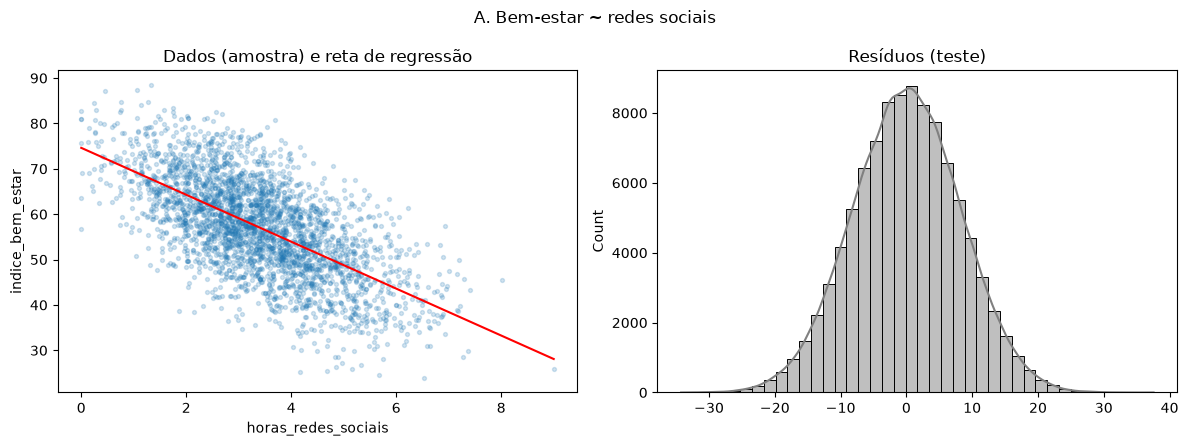

In [17]:
resultados = []
if "indice_bem_estar" in colunas:
    resultados.append(ajustar("A. Bem-estar ~ redes sociais", "indice_bem_estar", ["horas_redes_sociais"]))


B. Bem-estar ~ redes + sono
n = 500,000 | R² (teste) = 0.5107 | MAE = 5.902 | RMSE = 7.394
Intercepto: 30.457
  horas_redes_sociais                 coef = -1.9749 | beta padronizado = -0.2426
      -> +1 unidade em horas_redes_sociais muda indice_bem_estar em -1.975, mantendo as demais constantes
  horas_sono                          coef = +5.5803 | beta padronizado = +0.5123
      -> +1 unidade em horas_sono muda indice_bem_estar em +5.580, mantendo as demais constantes
Correlação entre preditores (checar colinearidade):


horas_redes_sociais,horas_sono
f64,f64
1.0,-0.761701
-0.761701,1.0


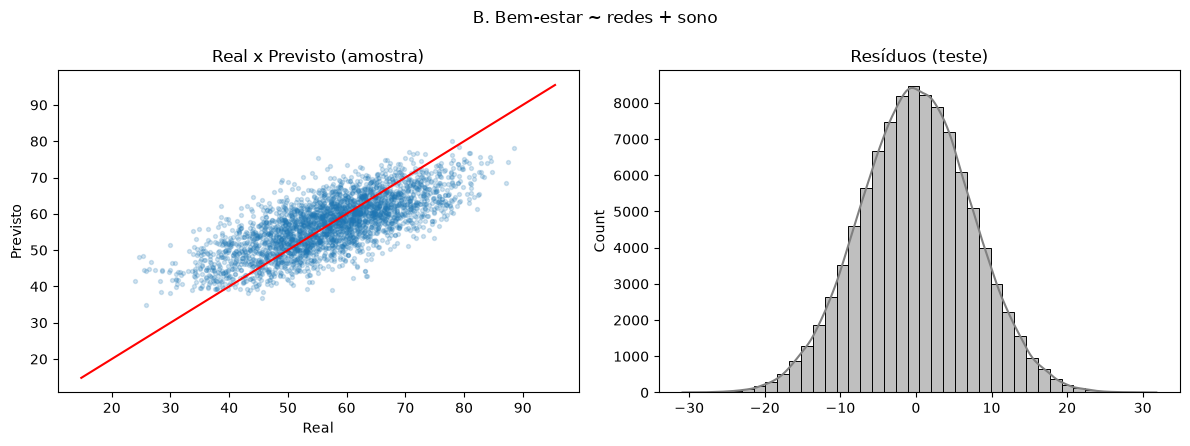

In [16]:
if "indice_bem_estar" in colunas:
    resultados.append(ajustar("B. Bem-estar ~ redes + sono", "indice_bem_estar",
                              ["horas_redes_sociais", "horas_sono"]))


C. Sono ~ redes
n = 500,000 | R² (teste) = 0.5801 | MAE = 0.504 | RMSE = 0.629
Intercepto: 7.916
  horas_redes_sociais                 coef = -0.5727 | beta padronizado = -0.7617
      -> +1 unidade em horas_redes_sociais muda horas_sono em -0.573, mantendo as demais constantes


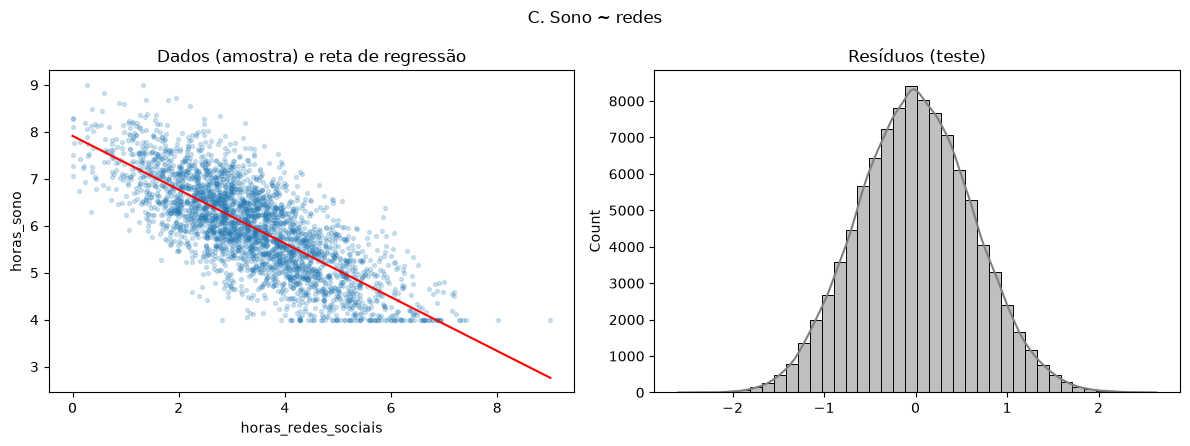

In [15]:
if "horas_sono" in colunas:
    resultados.append(ajustar("C. Sono ~ redes", "horas_sono", ["horas_redes_sociais"]))

### Modelos de desempenho
```
Frequência às aulas, capacidade de atenção e nota (se existir) como variáveis resposta.
```
---


D. Frequência ~ redes + sono
n = 500,000 | R² (teste) = 0.0791 | MAE = 4.795 | RMSE = 5.874
Intercepto: 91.400
  horas_redes_sociais                 coef = -1.0313 | beta padronizado = -0.2186
      -> +1 unidade em horas_redes_sociais muda taxa_frequencia_aulas em -1.031, mantendo as demais constantes
  horas_sono                          coef = +0.4750 | beta padronizado = +0.0761
      -> +1 unidade em horas_sono muda taxa_frequencia_aulas em +0.475, mantendo as demais constantes
Correlação entre preditores (checar colinearidade):


horas_redes_sociais,horas_sono
f64,f64
1.0,-0.761701
-0.761701,1.0


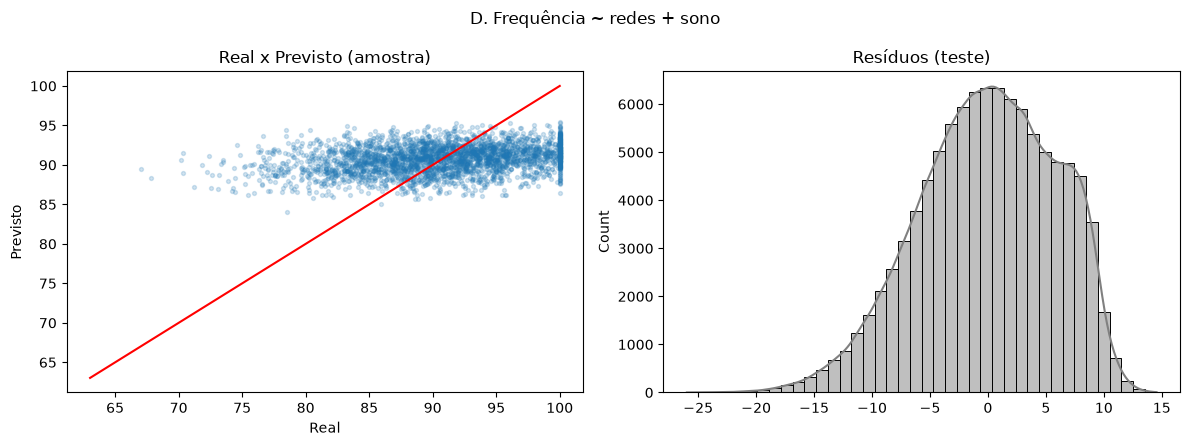

In [14]:
if "taxa_frequencia_aulas" in colunas:
    resultados.append(ajustar("D. Frequência ~ redes + sono", "taxa_frequencia_aulas",
                              ["horas_redes_sociais", "horas_sono"]))


E. Atenção ~ redes + sono
n = 500,000 | R² (teste) = 0.1972 | MAE = 3.672 | RMSE = 4.506
Intercepto: 54.333
  horas_redes_sociais                 coef = -1.3097 | beta padronizado = -0.3412
      -> +1 unidade em horas_redes_sociais muda capacidade_atencao_minutos em -1.310, mantendo as demais constantes
  horas_sono                          coef = +0.6300 | beta padronizado = +0.1210
      -> +1 unidade em horas_sono muda capacidade_atencao_minutos em +0.630, mantendo as demais constantes
Correlação entre preditores (checar colinearidade):


horas_redes_sociais,horas_sono
f64,f64
1.0,-0.761701
-0.761701,1.0


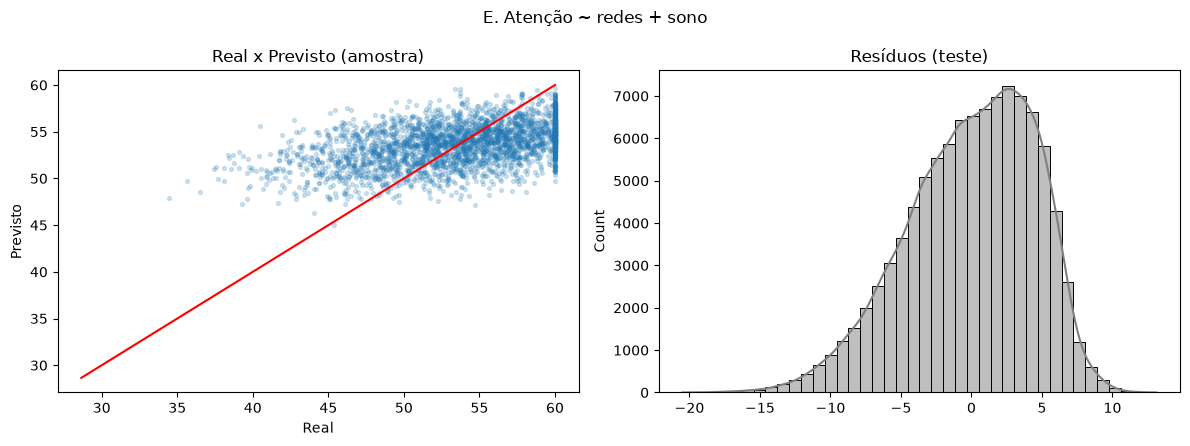

In [13]:
if "capacidade_atencao_minutos" in colunas:
    resultados.append(ajustar("E. Atenção ~ redes + sono", "capacidade_atencao_minutos",
                              ["horas_redes_sociais", "horas_sono"]))

### Comparação dos modelos
---

modelo,alvo,preditores,n,r2_teste,mae,rmse
str,str,str,i64,f64,f64,f64
"""A. Bem-estar ~ redes sociais""","""indice_bem_estar""","""horas_redes_sociais""",500000,0.4021,6.535,8.173


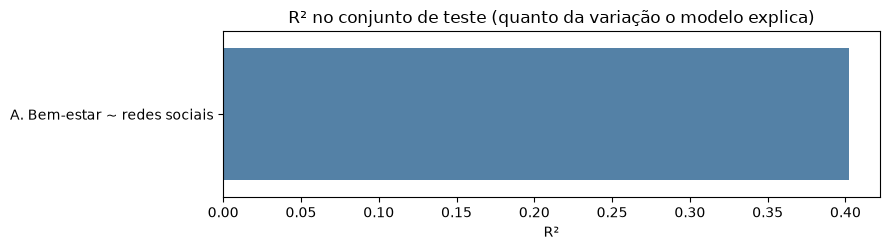

In [22]:
resumo = pl.DataFrame(resultados).sort("r2_teste", descending=True)
pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(60)
display(resumo)

pdf = resumo.to_pandas()
plt.figure(figsize=(9, 0.6 * len(pdf) + 2))
sns.barplot(data=pdf, y="modelo", x="r2_teste", color="steelblue")
plt.title("R² no conjunto de teste (quanto da variação o modelo explica)")
plt.xlabel("R²"); plt.ylabel("")
plt.tight_layout()
plt.show()

### Como interpretar (escreva sua conclusão com os números acima)
- **R²:** fração da variação explicada. R² baixo (ex.: < 0,10) significa que redes e IA sozinhas explicam pouco; outros fatores pesam mais. Isso é um resultado válido.
- **Coeficiente:** efeito de +1 unidade da variável (ex.: +1 hora de redes) mantendo as outras constantes. O sinal indica a direção.
- **Beta padronizado:** compara o peso entre variáveis com unidades diferentes (qual pesa mais: redes, IA ou sono?).
- **Treino/teste:** R² no teste próximo do R² no treino indica que o modelo generaliza.
- **Limites:** é associação, não causalidade; sono pode ser ao mesmo tempo efeito e causa do uso de redes.